# Estudo 04 – H3: a previsibilidade depende do horário?

Hipótese H3 das [notas](../NOTAS.md). Os estudos anteriores olharam o pregão **inteiro** de uma vez. Mas a abertura, o meio do dia e o fechamento são mercados diferentes (volatilidade, volume, quem está operando), e um efeito restrito a um horário pode sumir na média do dia.

Três perguntas:

1. **Momentum ou reversão entre candles seguidos**, hora a hora.
2. **Deriva por horário:** o preço tende a subir ou cair em certas horas?
3. **Momentum intradiário**, uma hipótese **da literatura**:
   - Gao, Han, Li & Zhou (2018), *Market intraday momentum* (Journal of Financial Economics): no S&P 500, o retorno da **primeira meia hora** prevê o da **última meia hora**;
   - Baltussen, Da, Lammers & Martens (2021), *Hedging demand and market intraday momentum* (JFE): o retorno **do resto do dia** prevê a última meia hora, por causa de fluxos de *hedge* perto do fechamento.

**Por que importa que a hipótese venha da literatura:** ela foi formulada **antes** de olharmos os nossos dados. Testá-la é uma comparação, não uma busca entre dezenas, então o problema das comparações múltiplas (Estudo 01, Seção 5) é bem menor.

**Dados:** WIN, só até 31/12/2024. Custos pelos cenários de `custos.py` (otimista 2,5 · **base 7,5** · conservador 12,5 pts).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sys, zoneinfo
from pathlib import Path
from scipy import stats

PASTA = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tt1_comum.py").exists())
sys.path.append(str(PASTA)); sys.path.append(str(PASTA / "frentes" / "estatistico"))
import tt1_comum as t
import custos as cu

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#a3a29c", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 1.6})
CUSTOS = {nome: p["custo_pts"] for nome, p in cu.CENARIOS.items()}

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
win = win[win.index < "2025-01-01"]

def corr_z(x, y):
    "Correlação e z robusto (aceita volatilidade variando)."
    x, y = np.asarray(x) - np.mean(x), np.asarray(y) - np.mean(y)
    return (x * y).sum() / np.sqrt((x * x).sum() * (y * y).sum()), (x * y).sum() / np.sqrt((x * x * y * y).sum())

def holm(pvals, alfa=0.05):
    "Correção de Holm: devolve True para os testes que continuam significativos depois de corrigir."
    p = np.asarray(pvals); ordem = np.argsort(p); m = len(p); ok = np.zeros(m, bool)
    for i, j in enumerate(ordem):
        if p[j] <= alfa / (m - i):
            ok[j] = True
        else:
            break
    return ok

## 1. Momentum ou reversão, hora a hora

Para candles de 5, 15 e 30 min (alinhados no relógio, começando em :00), medimos a correlação entre o retorno de um candle e o do seguinte (ρ₁), separando pela **hora** em que o candle começa. São ~30 testes ao todo.

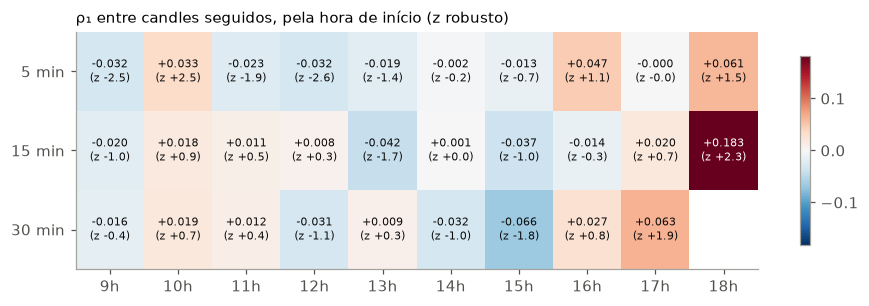

testes: 29 · significativos a 5% sem correção: 4 (esperado só por acaso: 1.5) · depois da correção de Holm: 0


In [2]:
linhas = []
for k in [5, 15, 30]:
    c = win.resample(f"{k}min").agg({"open": "first", "close": "last"}).dropna()
    d = pd.Series(c.index.normalize(), index=c.index)
    r = np.log(c.close).diff(); r[d != d.shift()] = np.nan
    prox = r.shift(-1); prox[d.shift(-1) != d] = np.nan
    df = pd.DataFrame({"r": r, "prox": prox, "hora": c.index.hour}).dropna()
    for h, g in df.groupby("hora"):
        if len(g) < 300:                       # o slot das 18h tem poucos pares em candles longos
            continue
        rho, z = corr_z(g.r, g.prox)
        linhas.append(dict(candle_min=k, hora=h, n=len(g), rho1=rho, z_robusto=z, p=2 * (1 - stats.norm.cdf(abs(z)))))
tab1 = pd.DataFrame(linhas)
tab1["signif_sem_correcao"] = tab1.p < 0.05
tab1["signif_holm"] = holm(tab1.p)

piv = tab1.pivot(index="candle_min", columns="hora", values="rho1")
pz = tab1.pivot(index="candle_min", columns="hora", values="z_robusto")
fig, ax = plt.subplots(figsize=(10, 2.8))
lim = np.nanmax(np.abs(piv.values))
im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        if not np.isnan(piv.values[i, j]):
            ax.text(j, i, f"{piv.values[i, j]:+.3f}\n(z {pz.values[i, j]:+.1f})", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(piv.values[i, j]) > 0.6 * lim else "#0b0b0b")
ax.set_xticks(range(piv.shape[1]), [f"{h}h" for h in piv.columns]); ax.set_yticks(range(piv.shape[0]), [f"{k} min" for k in piv.index])
ax.grid(False); ax.set_title("ρ₁ entre candles seguidos, pela hora de início (z robusto)", loc="left", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()
print(f"testes: {len(tab1)} · significativos a 5% sem correção: {tab1.signif_sem_correcao.sum()} "
      f"(esperado só por acaso: {0.05 * len(tab1):.1f}) · depois da correção de Holm: {tab1.signif_holm.sum()}")

**Correção para comparações múltiplas.** Com ~30 testes, esperamos ~1,5 "significativos" por puro acaso. Duas correções clássicas:

- **Bonferroni:** com m testes, exigir p < 0,05/m em cada um. Simples, mas muito exigente.
- **Holm:** ordenar os p-valores do menor para o maior e comparar o menor com 0,05/m, o segundo com 0,05/(m−1), e assim por diante, parando no primeiro que falhar. Dá a mesma garantia (chance ≤ 5% de **algum** falso positivo) e é menos conservadora.

**Leitura:** alguns horários passam de |z| = 2 sem correção (por exemplo, 5 min às 9h, 10h e 12h), com sinais trocados. É o número que o acaso produz, e **nenhum sobrevive à correção de Holm**. Não há momentum ou reversão confiável em nenhum horário.

## 2. Deriva por horário: o preço tende a subir ou cair em certas horas?

Retorno médio, em pontos, de cada candle de 60 min (abertura → fechamento), por hora.

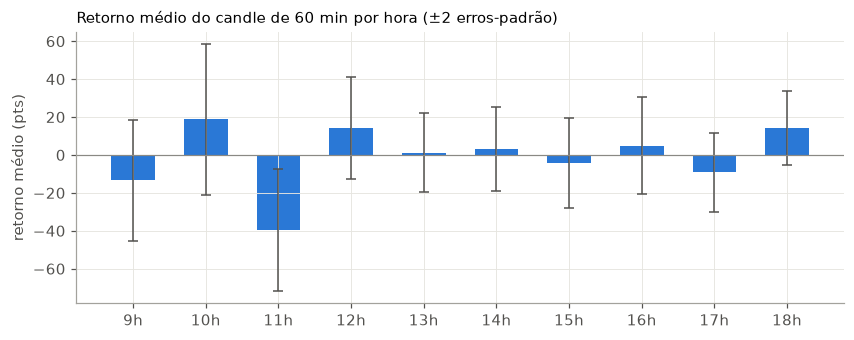

,n,media_pts,erro_padrao,t,p,signif_holm
datetime,,,,,,
9,927,-13.40,15.95,-0.84,0.40,False
10,927,18.72,19.81,0.94,0.34,False
11,929,-39.38,16.11,-2.44,0.01,False
12,929,14.12,13.46,1.05,0.29,False
13,933,1.13,10.40,0.11,0.91,False
14,933,3.14,11.01,0.29,0.78,False
15,933,-4.26,11.94,-0.36,0.72,False
16,934,4.91,12.88,0.38,0.70,False
17,934,-9.25,10.37,-0.89,0.37,False


In [3]:
c60 = win.resample("60min").agg({"open": "first", "close": "last"}).dropna()
pts = c60.close - c60.open
g = pts.groupby(c60.index.hour)
tab2 = pd.DataFrame({"n": g.size(), "media_pts": g.mean(), "erro_padrao": g.std() / np.sqrt(g.size())})
tab2["t"] = tab2.media_pts / tab2.erro_padrao
tab2["p"] = 2 * (1 - stats.norm.cdf(tab2.t.abs()))
tab2["signif_holm"] = holm(tab2.p.values)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar([f"{h}h" for h in tab2.index], tab2.media_pts, color=AZUL, width=0.6)
ax.errorbar(range(len(tab2)), tab2.media_pts, yerr=2 * tab2.erro_padrao, fmt="none", color="#52514e", capsize=3, lw=1)
ax.axhline(0, color=CINZA, lw=0.8); ax.set_ylabel("retorno médio (pts)")
ax.set_title("Retorno médio do candle de 60 min por hora (±2 erros-padrão)", loc="left", fontsize=10); plt.show()
tab2.round(2)

**Leitura:** o candle das 11h tem média de −39 pts (t = −2,4). Sozinho pareceria um efeito, mas é **1 em 10 testes**, e com Holm deixa de ser significativo. Nenhum horário tem deriva confiável.

## 3. Momentum intradiário: a hipótese da literatura

Para cada pregão completo (sem rolagem, sem buraco antes):

| Peça | Definição |
|---|---|
| 1ª meia hora (Gao et al.) | **fechamento de ontem** → fechamento do 30º minuto (inclui o gap da noite, como no artigo); variante sem o gap: abertura → 30º minuto |
| "resto do dia" (Baltussen et al.) | **fechamento de ontem** → 30 min antes do fim do pregão |
| última meia hora | 30 min antes do fim → fechamento do pregão (em pontos) |

O fim do pregão muda ao longo do ano (17:54 ou 18:24), então "30 min antes do fim" é calculado dia a dia.

A estratégia correspondente: **30 min antes do fim, entrar na direção do movimento do dia e sair no fechamento.** O resultado em pontos é o custo de equilíbrio.

In [4]:
def vencimentos(anos):
    out = []
    for y in anos:
        for m in [2, 4, 6, 8, 10, 12]:
            d15 = pd.Timestamp(y, m, 15); off = 2 - d15.weekday()
            off = off - 7 if off > 3 else off + 7 if off < -3 else off
            out.append(d15 + pd.Timedelta(days=off))
    return set(out)

NY, SP = zoneinfo.ZoneInfo("America/New_York"), zoneinfo.ZoneInfo("America/Sao_Paulo")
venc = vencimentos(range(2020, 2026))
linhas = []
for dia, x in win.groupby(win.index.normalize()):
    t0, fim = x.index[0], x.index[-1]
    cl = x.close
    preco = lambda ts: cl[cl.index <= ts].iloc[-1] if (cl.index <= ts).any() else np.nan   # dias curtos: âncora antes da abertura
    ny_fecha = pd.Timestamp(dia.date()).replace(hour=16).tz_localize(NY).tz_convert(SP).tz_localize(None)
    linha = dict(dia=dia, abertura=x.open.iloc[0], fechamento=cl.iloc[-1], fim=fim.strftime("%H:%M"),
                 ny_fecha=ny_fecha.strftime("%H:%M"), completo=(fim - t0) >= pd.Timedelta(hours=8),
                 p30=preco(t0 + pd.Timedelta(minutes=29)))
    for ant in [30, 60, 90, 120, 150, 180, 240, 300]:          # âncoras: X min antes do fim
        a = fim - pd.Timedelta(minutes=ant)
        linha[f"p_ant{ant}"] = preco(a)
        linha[f"p_ant{ant}_mais30"] = preco(a + pd.Timedelta(minutes=30))
    linhas.append(linha)
D = pd.DataFrame(linhas).set_index("dia")
D["fech_ontem"] = D.fechamento.shift()
D["dias_corridos"] = D.index.to_series().diff().dt.days
E = D[D.completo & ~D.index.isin(venc) & (D.dias_corridos <= 4)].copy()

E["ultima_meia_hora_pts"] = E.fechamento - E.p_ant30
preditores = {
    "1ª meia hora com o gap: fech. de ontem → 9:30 (Gao et al.)": np.log(E.p30 / E.fech_ontem),
    "variante: 1ª meia hora sem o gap (abertura → 9:30)": np.log(E.p30 / E.abertura),
    "resto do dia: fech. de ontem → fim−30 (Baltussen et al.)": np.log(E.p_ant30 / E.fech_ontem),
    "variante: abertura → fim−30": np.log(E.p_ant30 / E.abertura),
    "variante: 9:30 → fim−30": np.log(E.p_ant30 / E.p30),
}
linhas = []
for nome, x in preditores.items():
    rho, z = corr_z(x, E.ultima_meia_hora_pts)
    a_favor = np.sign(x) * E.ultima_meia_hora_pts
    linhas.append(dict(preditor=nome, n=len(E), rho=rho, z_robusto=z, custo_equilibrio_pts=a_favor.mean(),
                       erro_padrao=a_favor.std() / np.sqrt(len(E)), acerto=(a_favor > 0).mean()))
tab3 = pd.DataFrame(linhas)
print(f"pregões completos, sem rolagem e sem buraco antes: {len(E)} · desvio da última meia hora: {E.ultima_meia_hora_pts.std():.0f} pts")
tab3.round(3)

pregões completos, sem rolagem e sem buraco antes: 903 · desvio da última meia hora: 237 pts


,preditor,n,rho,z_robusto,custo_equilibrio_pts,erro_padrao,acerto
0,1ª meia hora com o gap: fech. de ontem → 9:30 ...,903,0.049,0.975,4.623,7.865,0.485
1,variante: 1ª meia hora sem o gap (abertura → 9...,903,0.082,1.987,13.040,7.851,0.497
2,resto do dia: fech. de ontem → fim−30 (Baltuss...,903,0.181,3.937,29.020,7.821,0.533
3,variante: abertura → fim−30,903,0.197,4.721,36.417,7.787,0.558
4,variante: 9:30 → fim−30,903,0.182,4.555,27.658,7.826,0.546


**Leitura:**

- **A hipótese de Gao et al. não se confirma** no WIN. Na definição do artigo (com o gap da noite), z ≈ 1. Sem o gap, z ≈ 2,0, limítrofe, com custo de equilíbrio de +13 ± 8 pts: não é robusto, e escolher a variante que funciona depois de ver os dados seria garimpar.
- **A de Baltussen et al. se confirma com folga:** o movimento do resto do dia continua na última meia hora. ρ ≈ 0,18–0,20, z robusto de 3,9 a 4,7, conforme a definição, e custo de equilíbrio de **+28 a +36 pts por operação**.
- O resultado **não depende da definição exata** do preditor: as três variantes dão o mesmo quadro. Bom sinal: um efeito frágil mudaria muito com detalhes.

Para comparação: ρ ≈ 0,19 é **mais de 10 vezes** a maior autocorrelação de candles do Estudo 01.

### 3.1 É algo do fim do pregão ou vale para qualquer hora?

Se for um momentum genérico ("o que subiu continua subindo"), deveria aparecer em qualquer horário. Mesma conta, com a âncora em vários pontos do dia: retorno de 9:30 até a âncora, contra o retorno dos 30 min seguintes.

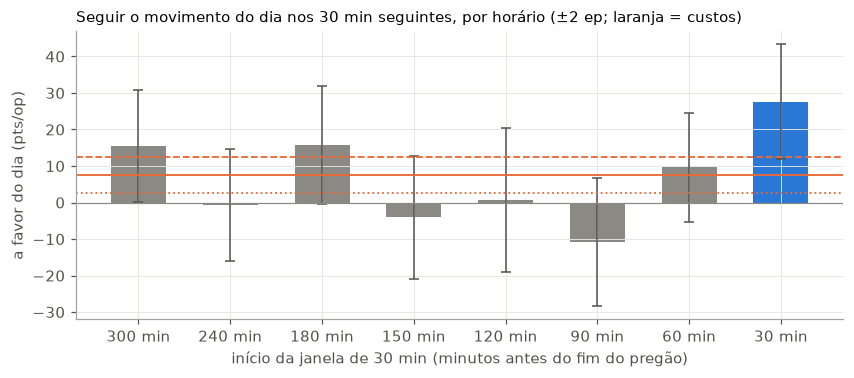

,minutos_antes_do_fim,rho,z_robusto,a_favor_pts,erro_padrao
0,300,0.006,0.162,15.465,7.616
1,240,0.017,0.468,-0.664,7.621
2,180,0.048,1.243,15.770,8.089
3,150,-0.030,-0.796,-4.081,8.474
4,120,-0.035,-0.512,0.692,9.912
5,90,-0.026,-0.666,-10.842,8.764
6,60,0.075,2.030,9.690,7.481
7,30,0.182,4.555,27.658,7.826


In [5]:
linhas = []
for ant in [300, 240, 180, 150, 120, 90, 60, 30]:
    x = np.log(E[f"p_ant{ant}"] / E.p30); y = E[f"p_ant{ant}_mais30"] - E[f"p_ant{ant}"]
    rho, z = corr_z(x, y); a_favor = np.sign(x) * y
    linhas.append(dict(minutos_antes_do_fim=ant, rho=rho, z_robusto=z, a_favor_pts=a_favor.mean(),
                       erro_padrao=a_favor.std() / np.sqrt(len(x))))
perfil = pd.DataFrame(linhas)

fig, ax = plt.subplots(figsize=(9, 3.4))
xs = [f"{a} min" for a in perfil.minutos_antes_do_fim]
ax.bar(xs, perfil.a_favor_pts, color=[AZUL if a == 30 else CINZA for a in perfil.minutos_antes_do_fim], width=0.6)
ax.errorbar(range(len(perfil)), perfil.a_favor_pts, yerr=2 * perfil.erro_padrao, fmt="none", color="#52514e", capsize=3, lw=1)
for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
    ax.axhline(CUSTOS[nome], color=LARANJA, lw=1.2, ls=estilo)
ax.axhline(0, color=CINZA, lw=0.8)
ax.set_xlabel("início da janela de 30 min (minutos antes do fim do pregão)"); ax.set_ylabel("a favor do dia (pts/op)")
ax.set_title("Seguir o movimento do dia nos 30 min seguintes, por horário (±2 ep; laranja = custos)", loc="left", fontsize=10)
plt.show()
perfil.round(3)

**Leitura:** o efeito é **específico da última meia hora**. Em qualquer outra janela do dia, seguir o movimento do dia dá ≈ 0 (dentro de ±2 erros-padrão). Não é um momentum genérico; é algo que acontece **no fechamento**.

### 3.2 Estabilidade: por ano, por horário do pregão, sem os dias extremos

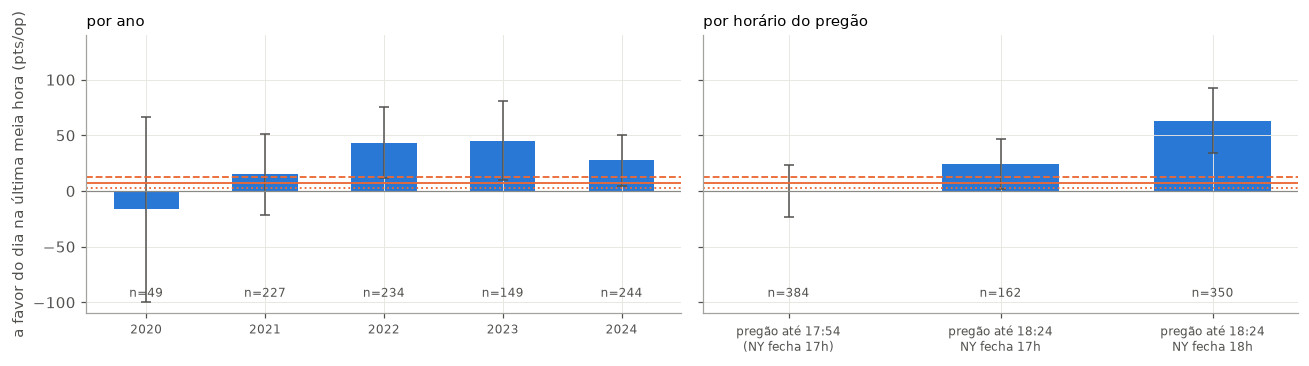

total: +29.0 ± 7.8 pts · mediana +25 · sem os 5% de dias mais extremos: +21.4


,n,media_pts,erro_padrao,acerto
dia,,,,
2020,49.0,-16.53,41.48,0.47
2021,227.0,15.02,18.17,0.48
2022,234.0,43.50,15.93,0.58
2023,149.0,45.17,17.79,0.52
2024,244.0,27.44,11.47,0.55


,n,media_pts,erro_padrao,acerto
regime,,,,
pregão até 17:54\n(NY fecha 17h),384.0,0.29,11.71,0.48
pregão até 18:24\nNY fecha 17h,162.0,24.07,11.15,0.57
pregão até 18:24\nNY fecha 18h,350.0,63.30,14.46,0.57


In [6]:
x = preditores["resto do dia: fech. de ontem → fim−30 (Baltussen et al.)"]
E["a_favor"] = np.sign(x) * E.ultima_meia_hora_pts
resumo = lambda v: pd.Series(dict(n=len(v), media_pts=v.mean(), erro_padrao=v.std() / np.sqrt(len(v)), acerto=(v > 0).mean()))

por_ano = E.groupby(E.index.year).a_favor.apply(resumo).unstack()
E["regime"] = np.select([E.fim == "17:54", (E.fim == "18:24") & (E.ny_fecha == "17:00"), (E.fim == "18:24") & (E.ny_fecha == "18:00")],
                        ["pregão até 17:54\n(NY fecha 17h)", "pregão até 18:24\nNY fecha 17h", "pregão até 18:24\nNY fecha 18h"], "outro")
por_regime = E[E.regime != "outro"].groupby("regime").a_favor.apply(resumo).unstack()

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, tab, titulo in [(axs[0], por_ano, "por ano"), (axs[1], por_regime, "por horário do pregão")]:
    lbl = [str(i) for i in tab.index]
    ax.bar(lbl, tab.media_pts, color=AZUL, width=0.55)
    ax.errorbar(range(len(tab)), tab.media_pts, yerr=2 * tab.erro_padrao, fmt="none", color="#52514e", capsize=3, lw=1)
    for nome, estilo in [("otimista", ":"), ("base", "-"), ("conservador", "--")]:
        ax.axhline(CUSTOS[nome], color=LARANJA, lw=1.2, ls=estilo)
    ax.axhline(0, color=CINZA, lw=0.8); ax.set_title(titulo, loc="left", fontsize=10)
    for i, n in enumerate(tab.n):
        ax.text(i, -95, f"n={int(n)}", ha="center", fontsize=8, color="#52514e")
    ax.tick_params(axis="x", labelsize=8)
axs[0].set_ylabel("a favor do dia na última meia hora (pts/op)"); axs[0].set_ylim(-110, 140)
fig.tight_layout(); plt.show()

corte = E.a_favor.abs().quantile(0.95)
print(f"total: {E.a_favor.mean():+.1f} ± {E.a_favor.std() / np.sqrt(len(E)):.1f} pts · mediana {E.a_favor.median():+.0f} · "
      f"sem os 5% de dias mais extremos: {E.a_favor[E.a_favor.abs() < corte].mean():+.1f}")
display(por_ano.round(2)); display(por_regime.round(2))

**Leitura:**

- **Por ano:** positivo em todos os anos completos (2021–2024), mais forte em 2022–2024. 2020 tem só 50 dias.
- **Sem os dias extremos:** continua positivo, e a mediana também. Não é efeito de meia dúzia de dias.
- **Por horário do pregão:** o efeito existe **só** quando o pregão vai até 18:24. Até 2023 isso valia de novembro a março; **desde 2024 o pregão vai sempre até 18:24** (verificado no Estudo 08), então esse grupo mistura nov–mar de 2020–23 com o ano todo de 2024, e o "regime" fica parcialmente confundido com o ano. Quando vai até 17:54 (mar–nov de 2021–23), é **zero** (+0,3 ± 12 pts). Quando vai até 18:24, aparece **tanto** nos dias em que Nova York fecha às 17h (+24 ± 11) **quanto** nos em que fecha às 18h, dentro da janela (+63 ± 14), mais forte no segundo caso.

**Mecanismo (incerto).** O efeito está preso ao **fechamento do próprio WIN**, não ao de Nova York: aparece mesmo quando NY já fechou. Candidatos:
- fluxos concentrados no fim do pregão: fundos que operam no fechamento, *hedge* de opções (o mecanismo de Baltussen et al.), a janela de cálculo do **ajuste diário** dos futuros e o fim do mercado à vista;
- a diferença entre os regimes de horário sugere que **o que acontece dentro da última meia hora** muda conforme a época do ano. Entender isso exigiria o calendário de horários da B3 de cada período, e é uma boa pergunta para o professor.

## 4. Candidato C2 e o poder da segunda validação

O efeito é forte (z ≈ 4), estável entre anos, robusto à definição e veio de uma hipótese **publicada**, não de uma busca. É o melhor candidato até aqui.

> **Candidato C2 (momentum intradiário no fechamento), pré-registrado:** em pregões completos, sem rolagem e não seguintes a buraco na base, calcular o retorno do **fechamento de ontem** até o fechamento do minuto que está **30 min antes do último minuto do pregão**. Entrar nesse minuto na direção desse retorno e sair no fechamento do último minuto. Avaliar com `custos.py` no cenário **conservador** (12,5 pts). Critério de sucesso: custo de equilíbrio > 12,5 pts **e** t > 2.

**Hipótese secundária (também pré-registrada, para reportar junto):** a mesma regra, só nos pregões que vão até 18:24. Ela veio de um **subgrupo descoberto nos dados** (Seção 3.2), não da literatura, então vale menos como evidência. Se a regra principal falhar e a secundária passar, o resultado é **sugestivo**, não confirmado.

> **Resultado (Estudo 08):** C2 e C2b **não se confirmaram** na segunda validação (−7 ± 15 e −6 ± 15 pts por operação).

**Ressalva importante: o poder da segunda validação.** De 01/2025 a 03/2026 são ~300 pregões. Com σ ≈ 240 pts por operação, o erro-padrão é ≈ 14 pts e o efeito mínimo detectável ≈ 39 pts (Estudo 03, Seção 1). Se o efeito verdadeiro for ~29 pts, a validação o **confirma só em cerca de metade das vezes**. Um "não confirmou" ali não será prova de que não existe, e um "confirmou" será bem mais informativo.

In [7]:
SIGMA, N = E.ultima_meia_hora_pts.std(), 300
ep = SIGMA / np.sqrt(N)
for efeito in [15, 20, 29, 37]:
    # passa no critério se: média estimada > 12,5 E t > 2  →  média > max(12,5, 2·ep)
    limiar = max(CUSTOS["conservador"], 2 * ep)
    poder = 1 - stats.norm.cdf((limiar - efeito) / ep)
    print(f"efeito verdadeiro {efeito} pts → chance de passar no critério com {N} pregões: {poder:.0%}")

efeito verdadeiro 15 pts → chance de passar no critério com 300 pregões: 18%
efeito verdadeiro 20 pts → chance de passar no critério com 300 pregões: 30%
efeito verdadeiro 29 pts → chance de passar no critério com 300 pregões: 55%
efeito verdadeiro 37 pts → chance de passar no critério com 300 pregões: 76%


## 5. Conclusões de H3

| Pergunta | Resposta |
|---|---|
| Momentum ou reversão em algum horário? | Não. Os poucos |z| > 2 são o que o acaso produz em ~30 testes; nenhum sobrevive à correção de Holm |
| Deriva por horário? | Não. O −39 pts das 11h não sobrevive à correção (1 em 10 testes) |
| A 1ª meia hora prevê a última (Gao et al.)? | Não: z ≈ 1 na definição do artigo; ≈ 2 (limítrofe, não robusto) sem o gap |
| O resto do dia prevê a última meia hora (Baltussen et al.)? | **Sim:** ρ ≈ 0,18–0,20, z ≈ 4, custo de equilíbrio de +28 a +36 pts. Específico do fechamento, positivo em todos os anos completos, robusto à definição. **Só existe nos pregões até 18:24** (nov–mar até 2023; o ano todo desde 2024); nos pregões até 17:54 é zero. **Não se confirmou na segunda validação (Estudo 08)** |
| Paga o custo? | No desenvolvimento, sim, até no cenário conservador: ~+17 pts líquidos por operação, uma por dia. **Candidato C2 pré-registrado**; a segunda validação tem poder de só ~50% para um efeito desse tamanho |

**Lições gerais:**

1. **Hipóteses da literatura valem mais que hipóteses garimpadas:** a comparação é uma só, não uma busca.
2. **Correção para comparações múltiplas (Holm)** sempre que se testa uma grade de horários, tamanhos ou limiares.
3. **Buscar o mecanismo:** saber *por que* um efeito existe (aqui, fluxos no fechamento) diz quando ele pode desaparecer. Por exemplo, se a B3 mudar os horários ou a forma de cálculo do ajuste.
4. **Relação com o projeto T+1:** o efeito não aparece como autocorrelação de candles seguidos. É uma previsão do **último** candle do dia usando o **dia inteiro** como informação. Um modelo T+1 que só olha os últimos candles não consegue vê-lo; um modelo com a feature "retorno acumulado do dia" e "minutos até o fim" poderia.